In [1]:
from goldpan.dataset import Dataset

ds = Dataset.open("../../../../goldsluice/examples/r76-registry.dataset.toml")
#ev = ds.read()         # the pulses with the processed quantities: one Events
q = ds.processed()     # only the processed quantities, no pulses: small, fast
#ev.quantities["Side2pC"]["current_max"]    # a record per channel, a field per output

## The processed quantities as RQs, with a cache

`goldpan.rqdata.load` reads RQ files (the format of the collaboration's processed files) as numpy arrays and keeps what it read in a
cache (`~/.cache/goldpan/rqdata`), so the second read of the same files is fast. `goldsluice` wrote the quantities as Parquet; the
next cell writes them as RQ files (one per dump, a branch `<channel>_<quantity>` for each, our names) in a folder outside the repository.
A run with `output_format = "root"` in the definition gives the same files directly.

In [2]:
from pathlib import Path

from goldpan import rqdata
from goldpan.adapters import rq_root

record = ds.spec.sources[0].detector_record
N = record.number                                      # the N of the zip<N> tree: from the registry (registry/run76.toml)
sensors = list(ds.spec.sources[0].read["channels"])    # Side2pC, Side2pF, ...: what P* stands for below
RQ_DIR = Path.home() / "goldsluice-output" / "r76-07221203-rq"

rq_root.write(q, RQ_DIR, detector=N)                   # about 2 s; a file that is rewritten is read again by rqdata, never served stale
sorted(RQ_DIR.glob("*.root"))[:2]

[WindowsPath('C:/Users/villanoa/goldsluice-output/r76-07221203-rq/07221203_2025_F0001.root'),
 WindowsPath('C:/Users/villanoa/goldsluice-output/r76-07221203-rq/07221203_2025_F0002.root')]

In [3]:
RQS = ["P*_adc_max", "P*_current_max", "P*_max_time_s"]      # P* = the six sensors
where = dict(detector=N, files=str(RQ_DIR / "{series}_F*.root"), phonon_channels=sensors, all_files=True)   # all_files: every dump

data = rqdata.load("07221203_2025", RQS, **where)      # the first time: reads the 30 files

07221203_2025: 1 series (30 files), 81992 events, 18 branches from the RQ files in 3.8 s


In [4]:
data = rqdata.load("07221203_2025", RQS, **where)      # the second time: from the cache

07221203_2025: 1 series (30 files), 81992 events, 18 branches from cache 07221203_2025_zip1_67be271eac_263f614b99.npz in 0.2 s


In [5]:
few = rqdata.load("07221203_2025", ["P*_current_max"], **where)   # fewer RQs than a cached read has: also from the cache
rqdata.cache_info()                                                # the entries; rqdata.cache_clear() removes them

07221203_2025: 1 series (30 files), 81992 events, 6 branches from cache 07221203_2025_zip1_67be271eac_263f614b99.npz in 0.1 s
C:\Users\villanoa\.cache\goldpan\rqdata: 1 entries, 18.4 MB


[{'file': '07221203_2025_zip1_67be271eac_263f614b99.npz',
  'bytes': 18375230,
  'modified': '2026-10-28 12:58'}]

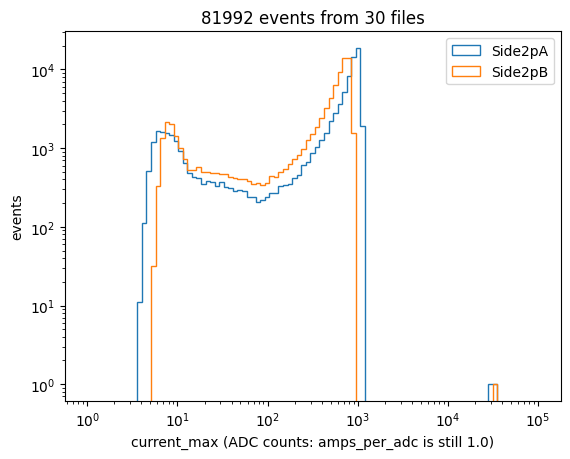

In [6]:
import matplotlib.pyplot as plt
import numpy as np

plt.hist(data["Side2pA_current_max"], bins=np.logspace(0, 5, 100), histtype="step", label="Side2pA")
plt.hist(data["Side2pB_current_max"], bins=np.logspace(0, 5, 100), histtype="step", label="Side2pB")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("current_max (ADC counts: amps_per_adc is still 1.0)"); plt.ylabel("events")
plt.title(f"{len(data['series'])} events from {len(data.files['07221203_2025'])} files"); plt.legend(); plt.show()